In [1]:
import os
import pickle

import matplotlib.pyplot as plt
import numpy
import torch
import numpy as np
from plotting_utils import *
import torch.nn as nn

import sys
sys.path.append('..')  # we're in the notebooks directory, so we need to move up one for splice.py

import matplotlib.colors as mcolors
from sklearn.linear_model import LinearRegression

from splice.splice import SPLICE

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)

os.environ['CUDA_LAUNCH_BLOCKING'] = "1"

%matplotlib inline
%config InlineBackend.figure_format='retina'

ModuleNotFoundError: No module named 'splice.base'; 'splice' is not a package

### Load the data

In [2]:
sim_name = 'random_18.9k'
train = pickle.load(
        open(os.path.join("..", "data", "lgn-v1", sim_name, f"{sim_name}_train.pkl"), "rb")
    )
test = pickle.load(
    open(os.path.join("..", "data", "lgn-v1", sim_name, f"{sim_name}_test.pkl"), "rb")
)

lgn_train = train["responses"]["lgn"]
v1_train = train["responses"]["v1"]

lgn_test = test["responses"]["lgn"]
v1_test = test["responses"]["v1"]

lgn_shared_only = pickle.load(
    open(os.path.join("..", "data", "lgn-v1", "shared", "shared_train.pkl"), "rb")
)["responses"]["lgn"]
v1_shared_only = pickle.load(
    open(os.path.join("..", "data", "lgn-v1", "shared", "shared_train.pkl"), "rb")
)["responses"]["v1"]

lgn_private_only = pickle.load(
    open(os.path.join("..", "data", "lgn-v1", "private", "private_train.pkl"), "rb")
)["responses"]["lgn"]
v1_private_only = pickle.load(
    open(os.path.join("..", "data", "lgn-v1", "private", "private_train.pkl"), "rb")
)["responses"]["v1"]

In [3]:
lgn_train.shape[0] + lgn_test.shape[0]

18900

In [3]:
lgn_shared_var = np.var(lgn_shared_only.reshape(-1,400), axis=0).mean()
lgn_private_var = np.var(lgn_private_only.reshape(-1,400), axis=0).mean()
v1_shared_var = np.var(v1_shared_only.reshape(-1,800), axis=0).mean()
v1_private_var = np.var(v1_private_only.reshape(-1,800), axis=0).mean()

In [6]:
v1_private_var/v1_shared_var

4.61632347780165

In [7]:
lgn_var = np.var(lgn_train.reshape(-1,400), axis=0).mean()
v1_var = np.var(v1_train.reshape(-1,400), axis=0).mean()

In [8]:
print(lgn_shared_var, lgn_private_var, lgn_var)
print(v1_shared_var, v1_private_var, v1_var)

0.006126642541626116 0.04036950647498659 0.04659313144452695
0.008760762872276232 0.04044251533074179 0.04919773747392446


In [14]:
noise_pcts = [1.6, 0.8, 0.4, 0.2, 0.1, 0.05]
lgn_snrs = np.zeros((6,2))
v1_snrs = np.zeros((6,2))
for i in range(len(noise_pcts)):
    pct = noise_pcts[i]
    lgn_noise = np.random.randn(18900, 400)
    lgn_noise *= np.sqrt(pct * lgn_var/np.var(lgn_noise.reshape(-1, 400), axis=0).mean())

    v1_noise = np.random.randn(18900, 800)
    v1_noise *= np.sqrt(pct * v1_var/np.var(v1_noise.reshape(-1, 800), axis=0).mean())

    lgn_snrs[i, 0] = lgn_shared_var/lgn_noise.reshape(-1, 400).var(axis=0).mean()
    lgn_snrs[i, 1] = lgn_private_var/lgn_noise.reshape(-1, 400).var(axis=0).mean()
    v1_snrs[i, 0] = v1_shared_var/v1_noise.reshape(-1, 800).var(axis=0).mean()
    v1_snrs[i, 1] = v1_private_var/v1_noise.reshape(-1, 800).var(axis=0).mean()

In [15]:
noise_pcts, lgn_snrs, v1_snrs

([1.6, 0.8, 0.4, 0.2, 0.1, 0.05],
 array([[ 0.08218275,  0.54151633],
        [ 0.1643655 ,  1.08303266],
        [ 0.32873099,  2.16606532],
        [ 0.65746199,  4.33213064],
        [ 1.31492397,  8.66426128],
        [ 2.62984794, 17.32852256]]),
 array([[ 0.1112953 ,  0.51377509],
        [ 0.22259059,  1.02755018],
        [ 0.44518119,  2.05510037],
        [ 0.89036237,  4.11020073],
        [ 1.78072475,  8.22040147],
        [ 3.5614495 , 16.44080293]]))

In [10]:
noise_pcts = [1.6, 0.8, 0.4, 0.2, 0.1, 0.05]
lgn_snrs = np.zeros((6,2))
v1_snrs = np.zeros((6,2))

for i in range(len(noise_pcts)):
    pct = noise_pcts[i]
    lgn_noise = np.random.randn(18900, 400)
    lgn_noise *= np.sqrt(1/pct * lgn_shared_var/np.var(lgn_noise.reshape(-1, 400), axis=0).mean())

    v1_noise = np.random.randn(18900, 800)
    v1_noise *= np.sqrt(1/pct * v1_shared_var/np.var(v1_noise.reshape(-1, 800), axis=0).mean())

    lgn_train_noise = torch.Tensor(lgn_train + lgn_noise[:lgn_train.shape[0], :]).to(device)
    lgn_test_noise = torch.Tensor(lgn_test + lgn_noise[lgn_train.shape[0]:, :]).to(device)

    v1_train_noise = torch.Tensor(v1_train + v1_noise[:v1_train.shape[0], :]).to(device)
    v1_test_noise = torch.Tensor(v1_test + v1_noise[v1_train.shape[0]:, :]).to(device)

    model = SPLICE(
        n_a = 400,
        n_b = 800,
        n_shared = 2,
        n_private_a = 1,
        n_private_b = 1,
        enc_layers = [200,200,200,200,200,200],
        dec_layers = [200,200,200,200,200,200],
        msr_layers = [200,200,200,200,200,200],
    ).to(device)

    model_filepath = os.path.join("..", "results", "models", "lgn-v1", f"{sim_name}_splice_snr{pct}.pt")
    model.fit(
       model.fit(
        lgn_train_noise, 
        v1_train_noise, 
        lgn_test_noise, 
        v1_test_noise,
        end_factor=1/25,
        batch_size=lgn_train.shape[0], 
        disent_start=10000, 
        msr_restart=25000,
        msr_iter_restart=1000,
        msr_iter_normal=1,
        c_disent=0.05, 
        epochs=25000, 
        weight_decay=1e-4,
        model_filepath=model_filepath
    )
    )


    model.load_state_dict(torch.load(model_filepath))
    model_filepath = os.path.join("..", "results", "models", "lgn-v1", f"{sim_name}_splice_isomap_{pct}.pt")

    model.fit_isomap_splice(
        lgn_train, 
        v1_train, 
        lgn_test, 
        v1_test, 
        lr=1e-3,
        end_factor=1/50,
        disent_start=3000, 
        msr_restart=25000,
        msr_iter_restart=1000,
        msr_iter_normal=1,
        c_disent=0.05, 
        epochs=25000, 
        weight_decay=1e-3,
        n_neighbors_shared_a=100, 
        n_neighbors_shared_b=100, 
        n_neighbors_private_a=100, 
        n_neighbors_private_b=100, 
        c_prox=50, 
        checkpoint_freq=500,
        model_filepath=model_filepath
    )


1/25000 |                                      |   0% [00:00<4:48:08,  1.45it/s]

Epoch 0:        A reconstruction: 0.0587 | 0.0563 	 B reconstruction: 0.0657 | 0.0635 	 Disentangling: 0.0000 | 0.0000 	 Measurement: 0.0000 | 2.3716


501/25000 |▋                                   |   2% [03:25<3:11:11,  2.14it/s]

Epoch 500:        A reconstruction: 0.0115 | 0.0123 	 B reconstruction: 0.0155 | 0.0160 	 Disentangling: 0.0000 | 8.7003 	 Measurement: 0.0000 | 206.3549


1001/25000 |█▍                                 |   4% [06:52<3:13:45,  2.06it/s]

...

Epoch 24000:        A reconstruction: 0.0042 | 0.0088 	 B reconstruction: 0.0056 | 0.0075 	 Disentangling: 0.0000 | 0.0023 	 Measurement: 1.9991 | 2.0466


24501/25000 |█████████████████████████████████▎|  98% [4:44:02<08:11,  1.02it/s]

Epoch 24500:        A reconstruction: 0.0042 | 0.0092 	 B reconstruction: 0.0056 | 0.0075 	 Disentangling: 0.0001 | 0.0050 	 Measurement: 1.9994 | 2.1000


25000/25000 |██████████████████████████████████| 100% [4:51:18<00:00,  1.43it/s]


TypeError: SPLICE.fit() missing 4 required positional arguments: 'b_train', 'a_validation', 'b_validation', and 'model_filepath'

In [333]:
lgn_shared_var/np.var(lgn_noise, axis=0).mean()

0.4000000000000001

In [21]:
# model = SPLICE(
#     n_a = 400,
#     n_b = 800,
#     n_shared = 2,
#     n_private_a = 1,
#     n_private_b = 1,
#     enc_layers = [200,200,200,200,200,200],
#     dec_layers = [200,200,200,200,200,200],
#     msr_layers = [200,200,200,200,200,200],
# ).to(device)

model_filepath = os.path.join("..", "results", "models", "lgn-v1", f"{sim_name}_splice_snr1.6.pt")
model.load_state_dict(torch.load(model_filepath))
z_a, z_b2a, z_a2b, z_b, m_b2a, m_a2b, a_hat, b_hat = model(lgn_test_noise, v1_test_noise)

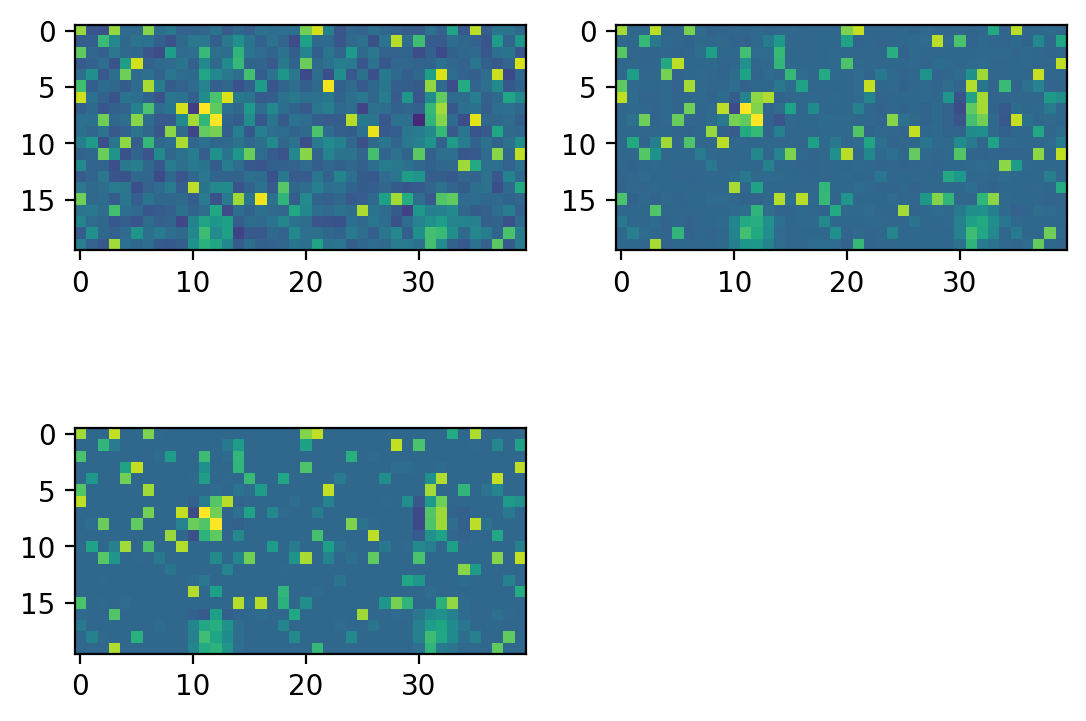

In [22]:
ind = 1341
plt.subplot(2,2,1)
plt.imshow(v1_test_noise[ind].detach().cpu().numpy().reshape(20,40), vmin=-0.5, vmax=1)


plt.subplot(2,2,2)
plt.imshow(b_hat[ind].detach().cpu().numpy().reshape(20, 40), vmin=-0.5, vmax=1)

plt.subplot(2,2,3)
plt.imshow(v1_test[ind].reshape(20,40), vmin=-0.5, vmax=1)

# plt.subplot(2,2,4)
# plt.imshow(lgn_shared_only[15120].reshape(20,20), vmin=-0.5, vmax=1)

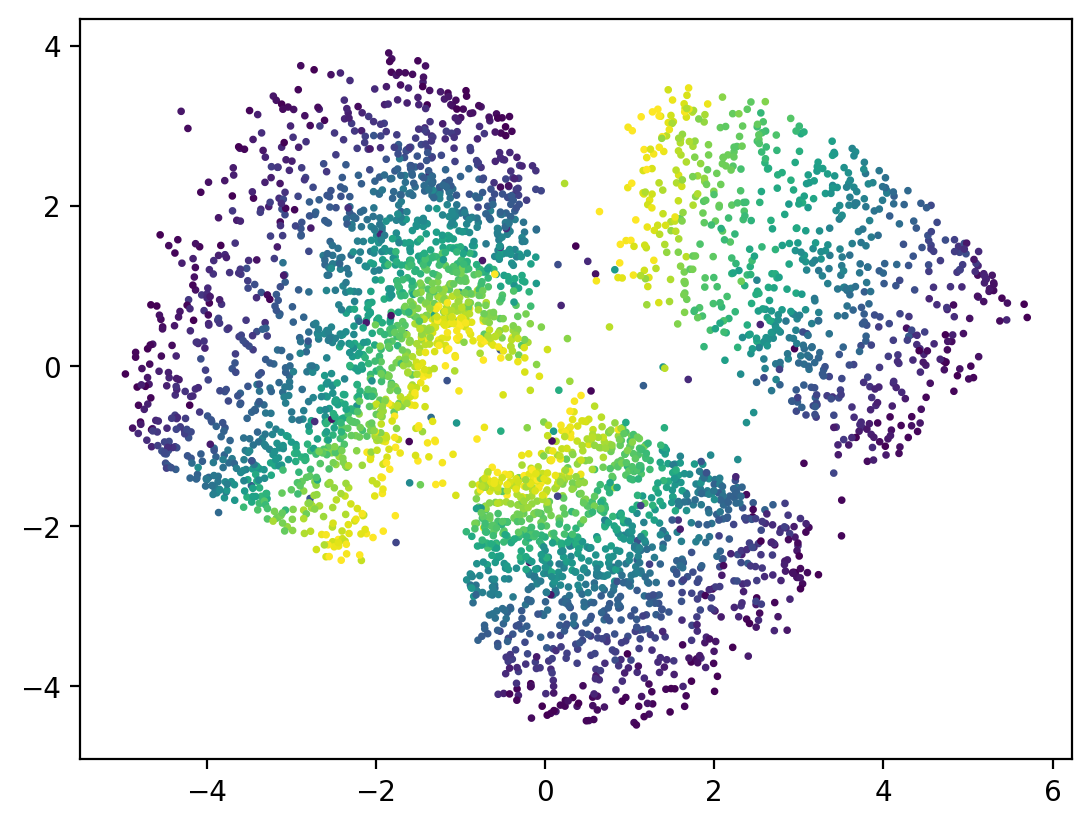

In [24]:
# z_b = z_b.detach().cpu().numpy()
z_a2b = z_a2b.detach().cpu().numpy()

plt.scatter(z_a2b[:,0], z_a2b[:,1], c= test["stim_params"]["x"], s=3)

### Model architecture

In [3]:
model = SPLICE(
    n_a = 400,
    n_b = 800,
    n_shared = 2,
    n_private_a = 1,
    n_private_b = 1,
    enc_layers = [200,200,200,200,200,200],
    dec_layers = [200,200,200,200,200,200],
    msr_layers = [200,200,200,200,200,200],
).to(device)

### Train/load model

In [5]:
trainNonIsomapModel = False
model_filepath = os.path.join("..", "results", "models", "lgn-v1", f"{sim_name}_splice_wd.pt")

if trainNonIsomapModel:
    model.fit(
        lgn_train, 
        v1_train, 
        lgn_test, 
        v1_test,
        end_factor=1/50,
        batch_size=lgn_train.shape[0], 
        disent_start=10000, 
        msr_iter_restart=500,
        msr_iter_normal=1,
        c_disent=0.05, 
        epochs=50000, 
        weight_decay=1e-4,
        model_filepath=model_filepath
    )
else:
    model.load_state_dict(torch.load(model_filepath, map_location=device))

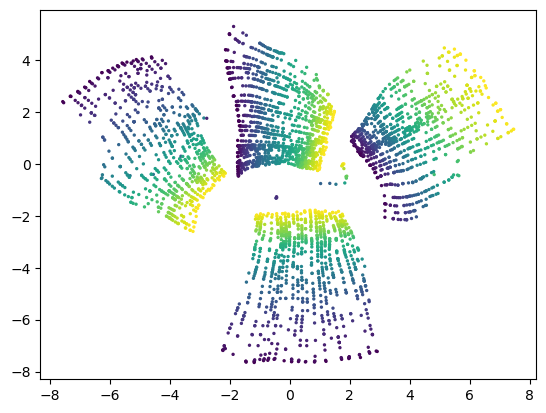

In [5]:
z_a, z_b2a, z_a2b, z_b, m_b2a, m_a2b, a_hat, b_hat = model(
                        lgn_test, v1_test
                    )
plt.scatter(z_a2b[:,0].detach().cpu().numpy(), z_a2b[:,1].detach().cpu().numpy(), c=test["stim_params"]["x"]  ,s=2)

In [10]:
class encoder_lin(nn.Module):
    def __init__(self, nInputs, nOutputs):
        super(encoder_lin, self).__init__()
        self.layers = nn.ModuleList()
        self.layers.append(nn.Linear(nInputs, nOutputs))
        
    def forward(self, x):
        return self.layers[0](x)
    
class decoder_lin(nn.Module):
    def __init__(self, nInputs, nOutputs):
        super(decoder_lin, self).__init__()
        self.layers = nn.ModuleList()
        self.layers.append(nn.Linear(nInputs, nOutputs))
        
    def forward(self, x):
        return self.layers[0](x)

class network_lin(nn.Module):
    def __init__(self, nInputs, nOutputs, bottleDim):
        super(network_lin, self).__init__()
        self.encoder = encoder_lin(nInputs, bottleDim)
        self.decoder = decoder_lin(bottleDim, nOutputs)
    def forward(self, x):
        return self.decoder(self.encoder(x))

In [14]:
model = network_lin(lgn_train.shape[1], v1_train.shape[1], 100).to(device)


optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, total_iters = 10000, start_factor=1, end_factor=1/100)
loss_fn = nn.MSELoss()

for epoch in range(20000):
    out = model(lgn_train)
    loss = loss_fn(out, v1_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    scheduler.step()

    if epoch % 1000 == 0:
        print("EPOCH %d | train loss: %.4f | test loss: %.4f" % (epoch, loss.detach().cpu().numpy(), loss_fn(model(lgn_test), v1_test).detach().cpu().numpy()))

EPOCH 0 | train loss: 0.0675 | test loss: 0.0645
EPOCH 1000 | train loss: 0.0402 | test loss: 0.0415
EPOCH 2000 | train loss: 0.0400 | test loss: 0.0415
EPOCH 3000 | train loss: 0.0400 | test loss: 0.0415
EPOCH 4000 | train loss: 0.0400 | test loss: 0.0415
EPOCH 5000 | train loss: 0.0400 | test loss: 0.0416
EPOCH 6000 | train loss: 0.0400 | test loss: 0.0416
EPOCH 7000 | train loss: 0.0400 | test loss: 0.0416
EPOCH 8000 | train loss: 0.0400 | test loss: 0.0416


KeyboardInterrupt: 

In [17]:
s1 = torch.var(v1_test, dim=0).mean()
s2 = torch.var(v1_test - model(lgn_test), dim=0).mean()
print(1-s2/s1)

tensor(0.1545, device='cuda:0', grad_fn=<RsubBackward1>)


### Iso: Train/Load model

In [4]:
trainIsomapModel = False
model_filepath = os.path.join("..", "results", "models", "lgn-v1", f"{sim_name}_splice_isomap_wd.pt")

if trainIsomapModel:
    model.fit_isomap_splice(
        lgn_train, 
        v1_train, 
        lgn_test, 
        v1_test, 
        lr=1e-3,
        end_factor=1/50,
        disent_start=3000, 
        msr_restart=1000,
        msr_iter_restart=500,
        msr_iter_normal=1,
        c_disent=0.05, 
        epochs=25000, 
        weight_decay=1e-3,
        n_neighbors=100, 
        c_prox=50, 
        print_every=500,
        model_filepath=model_filepath)
else:
    model.load_state_dict(torch.load(model_filepath, map_location=device))

In [6]:
s1 = torch.var(lgn_test, dim=0).mean()
s2 = torch.var(lgn_test - a_hat, dim=0).mean()
print(1-s2/s1)

tensor(0.9922, device='cuda:0', grad_fn=<RsubBackward1>)


In [7]:
s1 = torch.var(v1_test, dim=0).mean()
s2 = torch.var(v1_test - b_hat, dim=0).mean()
print(1-s2/s1)

tensor(0.9977, device='cuda:0', grad_fn=<RsubBackward1>)


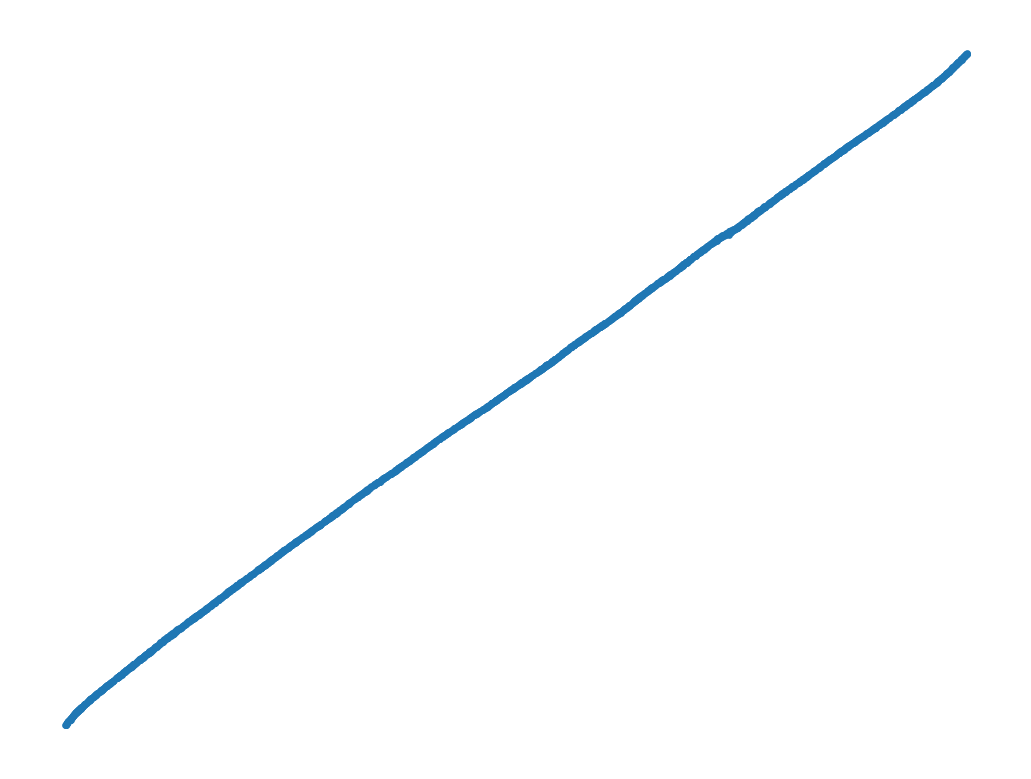

In [5]:
z_a, z_b2a, z_a2b, z_b, m_b2a, m_a2b, a_hat, b_hat = model(
                        lgn_test, v1_test
                    )
plt.scatter(z_b.detach().cpu().numpy(), test['stim_params']['v1_p'], s=2)
plt.axis('off')
plt.xlabel('private B: z_b')
plt.ylabel('V1 private: v1_p')

plt.savefig('../figures/SPLICE_lgn-v1_z-b.png', dpi=300, bbox_inches='tight', transparent=True)

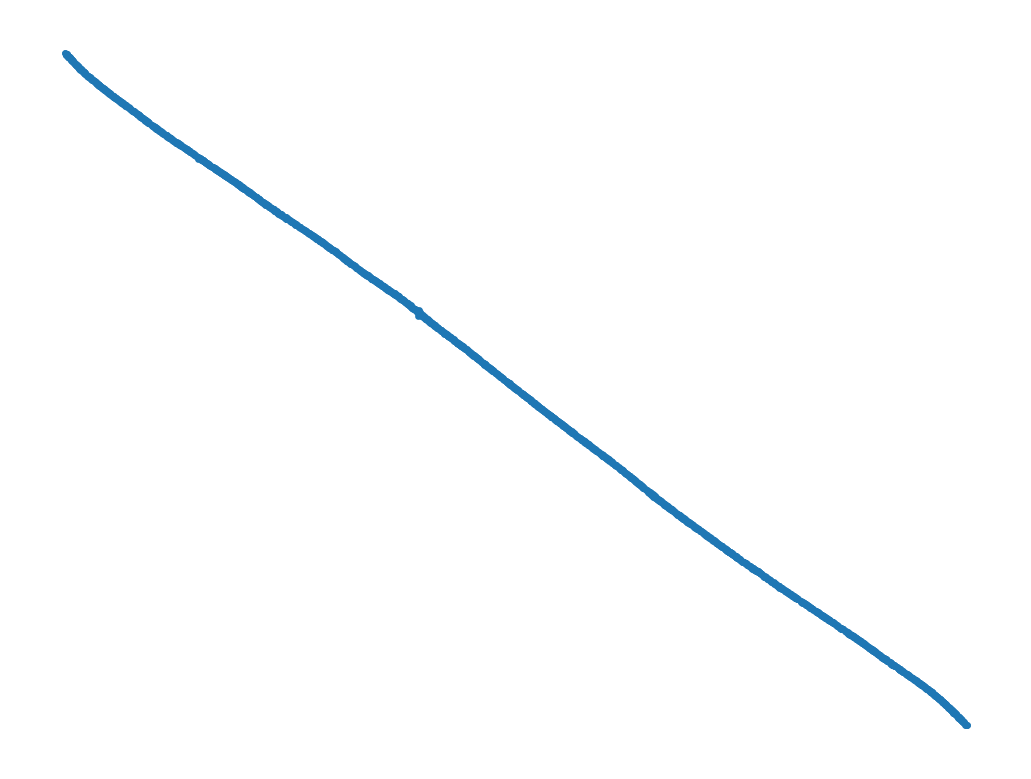

In [28]:
plt.scatter(z_a.detach().cpu().numpy(), test['stim_params']['lgn_p'], s=2)
plt.axis('off')
plt.xlabel('private B: z_b')
plt.ylabel('V1 private: v1_p')

plt.savefig('../figures/SPLICE_lgn-v1_z-a.png', dpi=300, bbox_inches='tight', transparent=True)

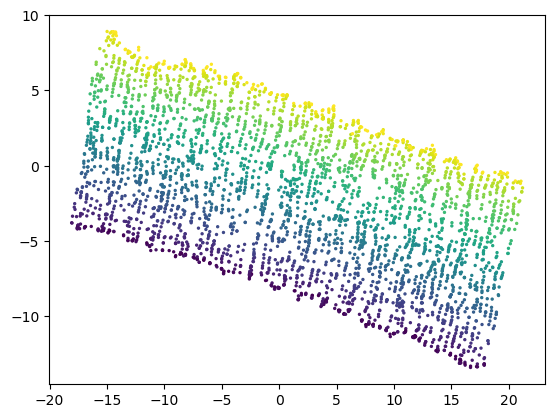

In [8]:
plt.scatter(z_b2a[:,0].detach().cpu().numpy(), z_b2a[:,1].detach().cpu().numpy(), c=test["stim_params"]["x"]  ,s=2)

### Linear regression for latent space quality

#### without isomap

In [9]:
model = SPLICE(
    n_a = 400,
    n_b = 800,
    n_shared = 2,
    n_priv_a = 1,
    n_priv_b = 1,
    layers_enc = [200,200,200,200,200,200],
    layers_dec = [200,200,200,200,200,200],
    layers_msr = [200,200,200,200,200,200],
).to(device)
model_filepath = os.path.join("..", "results", "models", "lgn-v1", f"{sim_name}_splice_wd.pt")
model.load_state_dict(torch.load(model_filepath, map_location=device))

<All keys matched successfully>

In [10]:
train_z_a, train_z_b2a, train_z_a2b, train_z_b, _,_,_,_ = model(
                        lgn_train, v1_train
                    )
test_z_a, test_z_b2a, test_z_a2b, test_z_b, _,_,_,_ = model(
                        lgn_test, v1_test
                    )

train_z_a = train_z_a.detach().cpu().numpy()
train_z_b2a = train_z_b2a.detach().cpu().numpy()
train_z_a2b = train_z_a2b.detach().cpu().numpy()
train_z_b = train_z_b.detach().cpu().numpy()

test_z_a = test_z_a.detach().cpu().numpy()
test_z_b2a = test_z_b2a.detach().cpu().numpy()
test_z_a2b = test_z_a2b.detach().cpu().numpy()
test_z_b = test_z_b.detach().cpu().numpy()

In [11]:
reg = LinearRegression().fit(train_z_a, train["stim_params"]["lgn_p"])
print("LGN private decoding from z_a R^2: %.4f" % reg.score(test_z_a, test["stim_params"]["lgn_p"]))

reg = LinearRegression().fit(train_z_b, train["stim_params"]["v1_p"])
print("V1 private decoding from z_b R^2: %.4f" % reg.score(test_z_b, test["stim_params"]["v1_p"]))

reg = LinearRegression().fit(train_z_b2a, train["stim_params"]["x"])
print("X decoding from shared R^2: %.4f" % reg.score(test_z_b2a, test["stim_params"]["x"]))

reg = LinearRegression().fit(train_z_b2a, train["stim_params"]["y"])
print("Y decoding from shared R^2: %.4f" % reg.score(test_z_b2a, test["stim_params"]["y"]))

reg = LinearRegression().fit(train_z_a2b, train["stim_params"]["x"])
print("X decoding from shared a2b R^2: %.4f" % reg.score(test_z_a2b, test["stim_params"]["x"]))

reg = LinearRegression().fit(train_z_a2b, train["stim_params"]["y"])
print("Y decoding from shared a2b R^2: %.4f" % reg.score(test_z_a2b, test["stim_params"]["y"]))

LGN private decoding from z_a R^2: 0.6534
V1 private decoding from z_b R^2: 0.0043
X decoding from shared R^2: 0.1343
Y decoding from shared R^2: 0.7158
X decoding from shared a2b R^2: 0.0492
Y decoding from shared a2b R^2: 0.0994


#### with isomap

In [12]:
model = SPLICE(
    n_a = 400,
    n_b = 800,
    n_shared = 2,
    n_priv_a = 1,
    n_priv_b = 1,
    layers_enc = [200,200,200,200,200,200],
    layers_dec = [200,200,200,200,200,200],
    layers_msr = [200,200,200,200,200,200],
).to(device)
model_filepath = os.path.join("..", "results", "models", "lgn-v1", f"{sim_name}_splice_isomap_wd.pt")
model.load_state_dict(torch.load(model_filepath, map_location=device))

<All keys matched successfully>

In [13]:
train_z_a, train_z_b2a, train_z_a2b, train_z_b, _,_,_,_ = model(
                        lgn_train, v1_train
                    )
test_z_a, test_z_b2a, test_z_a2b, test_z_b, _,_,_,_ = model(
                        lgn_test, v1_test
                    )

train_z_a = train_z_a.detach().cpu().numpy()
train_z_b2a = train_z_b2a.detach().cpu().numpy()
train_z_a2b = train_z_a2b.detach().cpu().numpy()
train_z_b = train_z_b.detach().cpu().numpy()

test_z_a = test_z_a.detach().cpu().numpy()
test_z_b2a = test_z_b2a.detach().cpu().numpy()
test_z_a2b = test_z_a2b.detach().cpu().numpy()
test_z_b = test_z_b.detach().cpu().numpy()

In [14]:
reg = LinearRegression().fit(train_z_a, train["stim_params"]["lgn_p"])
print("LGN private decoding from z_a R^2: %.4f" % reg.score(test_z_a, test["stim_params"]["lgn_p"]))

reg = LinearRegression().fit(train_z_b, train["stim_params"]["v1_p"])
print("V1 private decoding from z_b R^2: %.4f" % reg.score(test_z_b, test["stim_params"]["v1_p"]))

reg = LinearRegression().fit(train_z_b2a, train["stim_params"]["x"])
print("X decoding from shared b2a R^2: %.4f" % reg.score(test_z_b2a, test["stim_params"]["x"]))

reg = LinearRegression().fit(train_z_b2a, train["stim_params"]["y"])
print("Y decoding from shared b2a R^2: %.4f" % reg.score(test_z_b2a, test["stim_params"]["y"]))

reg = LinearRegression().fit(train_z_a2b, train["stim_params"]["x"])
print("X decoding from shared a2b R^2: %.4f" % reg.score(test_z_a2b, test["stim_params"]["x"]))

reg = LinearRegression().fit(train_z_a2b, train["stim_params"]["y"])
print("Y decoding from shared a2b R^2: %.4f" % reg.score(test_z_a2b, test["stim_params"]["y"]))


LGN private decoding from z_a R^2: 0.9997
V1 private decoding from z_b R^2: 0.9998
X decoding from shared b2a R^2: 0.9953
Y decoding from shared b2a R^2: 0.9996
X decoding from shared a2b R^2: 0.9984
Y decoding from shared a2b R^2: 0.9999


### Plot Isomap shared space

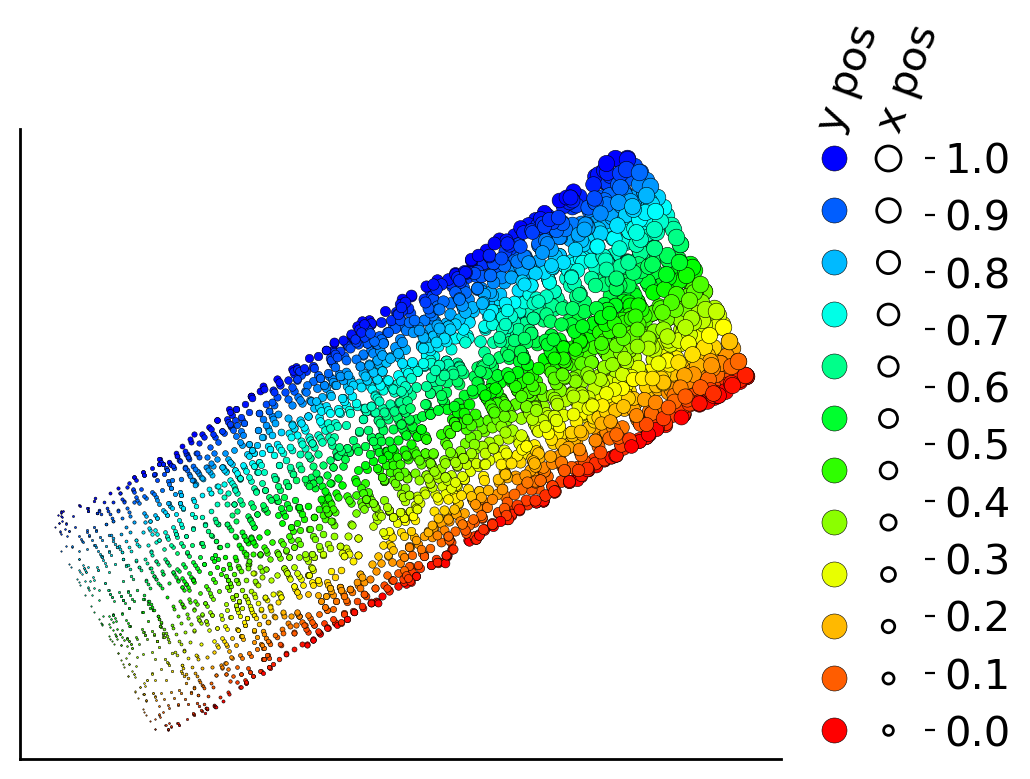

In [19]:
z_x, z_s_x, z_s_y, z_y, m_x, m_y, x_hat, y_hat = model(lgn_test, v1_test)

z_x = z_x.detach().cpu().numpy()
z_s_x = z_s_x.detach().cpu().numpy()
z_s_y = z_s_y.detach().cpu().numpy()
z_y = z_y.detach().cpu().numpy()

xpos_train = train["stim_params"]["x"]
ypos_train = train["stim_params"]["y"]
lgn_p_train = train["stim_params"]["lgn_p"]
v1_p_train = train["stim_params"]["v1_p"]

xpos_test = test["stim_params"]["x"]
ypos_test = test["stim_params"]["y"]
lgn_p_test = test["stim_params"]["lgn_p"]
v1_p_test = test["stim_params"]["v1_p"]

# colors for x and y positions, normalized to [0,1]
xcolrange = (xpos_test - xpos_test.min())/(xpos_test.max() - xpos_test.min())
ycolrange = (ypos_test - ypos_test.min())/(ypos_test.max() - ypos_test.min())

maxMarkerSize = 6
minMarkerSize = 0.5

# --------------------------------------------------------
#
#  Main plot
#
# --------------------------------------------------------

plt.figure(figsize=(12,10))
plt.subplot(2, 2, 1)    
for i in range(z_s_y.shape[0]):
    # Each point gets a color based on its x position
    red_blue = mcolors.to_rgb(mcolors.hsv_to_rgb([0.666 * xcolrange[i], 1.0, 1.0]))
    # Each point gets a size based on its y position
    plt.plot(-z_s_y[i,0], -z_s_y[i,1], 'o', color=red_blue, 
             markersize=ycolrange[i]*(maxMarkerSize-minMarkerSize)+minMarkerSize, 
             markeredgecolor='black', markeredgewidth=0.2)
# plt.title("LGN shared")
plt.xticks([]); plt.yticks([])
axisWidthChange(0.9, 'l')
axisHeightChange(0.9, 't')
# plt.gca().set_frame_on(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['bottom'].set_linewidth(1)
plt.gca().spines['left'].set_linewidth(1)


# ----- add arrows to the axes -- not quite yet working -----
# from matplotlib.patches import FancyArrowPatch

# arrowprops=dict(arrowstyle="<|-", color="k", lw=1)
# xlim = plt.gca().get_xlim()
# ylim = plt.gca().get_ylim()
# # Adding arrowheads: x-axis and y-axis (start point, end point, arrow properties):
# plt.gca().add_patch(FancyArrowPatch((xlim[0], ylim[0]), (xlim[1], ylim[0]), **arrowprops))  # x-axis arrow
# plt.gca().add_patch(FancyArrowPatch((xlim[0], ylim[0]), (xlim[0], ylim[1]), **arrowprops))  # y-axis arrow
# # Adjust the axis limits to make sure arrows are fully visible
# plt.xlim(-49, 5)
# plt.ylim(-18, 1)
# ---- end add arrows ----

# --------------------------------------------------------
#
#  plot making legend for dot size and color
#
# --------------------------------------------------------
ax2 = plt.axes(position=plt.gca().get_position())
axisWidthChange(0.15, 'r')
axisMove(0.06, 0)
plt.xticks([]); plt.yticks([])
numItems = 12  # number of vertical color and dot size entries
for i in range(numItems):
    # First the colored dots
    red_blue = mcolors.to_rgb(mcolors.hsv_to_rgb([0.666 * i/(numItems-1), 1.0, 1.0]))
    plt.plot(0, i/(numItems-1), 'o', color=red_blue, 
             markersize=maxMarkerSize+3, 
             markeredgecolor='black', markeredgewidth=0.2)
    # Then the different sized dots
    plt.plot(1.2, i/(numItems-1), 'o', color='w',
             markersize=(i/11)*(maxMarkerSize-minMarkerSize)+minMarkerSize+3, 
             markeredgecolor='black', markeredgewidth=1)
    plt.xlim(-0.5,2)
plt.gca().set_frame_on(False)
plt.yticks(np.arange(0,1.1,0.1));
plt.gca().set_yticklabels(np.round(np.arange(0,1.1,0.1), 2), fontsize=15)
ax2.tick_params(axis='y', labelright=True, labelleft=False, left=False, right=True)
plt.text(-0.5, 1.05, "y pos", fontsize=15, rotation=70); # , transform=ax2.transAxes);
plt.text( 0.8, 1.05, "x pos", fontsize=15, rotation=70); # , transform=ax2.transAxes);


# --------------------------------------------------------
#
#  save the plot
#
# --------------------------------------------------------
plt.savefig("../Figures/isomap_shared_LGN_raw.svg", bbox_inches='tight', transparent=True, dpi=300)


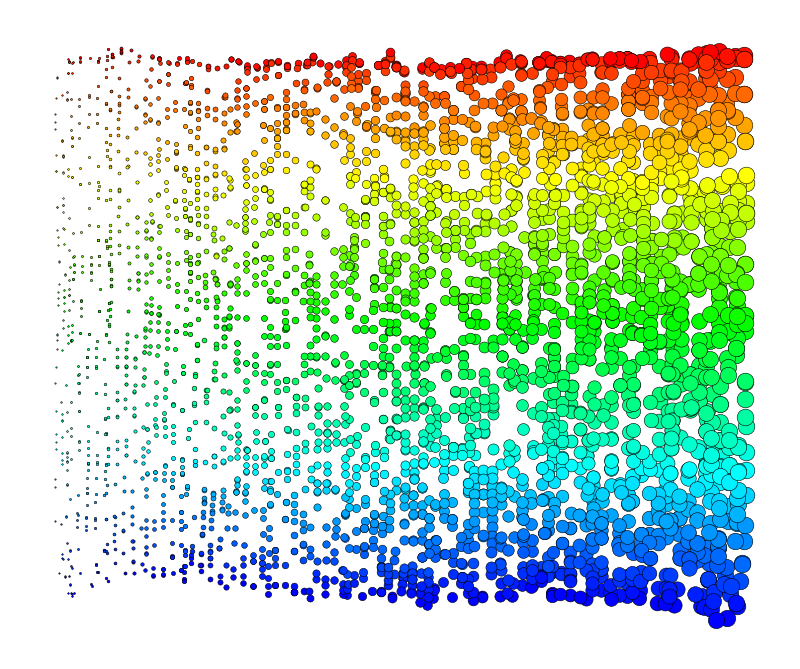

In [26]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
zsy_pc = pca.fit_transform(z_s_y)

# colors for x and y positions, normalized to [0,1]
xcolrange = (xpos_test - xpos_test.min())/(xpos_test.max() - xpos_test.min())
ycolrange = (ypos_test - ypos_test.min())/(ypos_test.max() - ypos_test.min())

maxMarkerSize = 6
minMarkerSize = 0.5

# --------------------------------------------------------
#
#  Main plot
#
# --------------------------------------------------------

plt.figure(figsize=(12,10))
plt.subplot(2, 2, 1)    
for i in range(z_s_y.shape[0]):
    # Each point gets a color based on its x position
    red_blue = mcolors.to_rgb(mcolors.hsv_to_rgb([0.666 * xcolrange[i], 1.0, 1.0]))
    # Each point gets a size based on its y position
    plt.plot(-zsy_pc[i,0], -zsy_pc[i,1], 'o', color=red_blue, 
             markersize=ycolrange[i]*(maxMarkerSize-minMarkerSize)+minMarkerSize, 
             markeredgecolor='black', markeredgewidth=0.2)
# plt.title("LGN shared")
plt.xticks([]); plt.yticks([])
axisWidthChange(0.9, 'l')
axisHeightChange(0.9, 't')
plt.gca().set_frame_on(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
# plt.gca().spines['bottom'].set_linewidth(1)
# plt.gca().spines['left'].set_linewidth(1)


# ----- add arrows to the axes -- not quite yet working -----
# from matplotlib.patches import FancyArrowPatch

# arrowprops=dict(arrowstyle="<|-", color="k", lw=1)
# xlim = plt.gca().get_xlim()
# ylim = plt.gca().get_ylim()
# # Adding arrowheads: x-axis and y-axis (start point, end point, arrow properties):
# plt.gca().add_patch(FancyArrowPatch((xlim[0], ylim[0]), (xlim[1], ylim[0]), **arrowprops))  # x-axis arrow
# plt.gca().add_patch(FancyArrowPatch((xlim[0], ylim[0]), (xlim[0], ylim[1]), **arrowprops))  # y-axis arrow
# # Adjust the axis limits to make sure arrows are fully visible
# plt.xlim(-49, 5)
# plt.ylim(-18, 1)
# ---- end add arrows ----

# --------------------------------------------------------
#
#  plot making legend for dot size and color
#
# --------------------------------------------------------
# ax2 = plt.axes(position=plt.gca().get_position())
# axisWidthChange(0.15, 'r')
# axisMove(0.06, 0)
# plt.xticks([]); plt.yticks([])
# numItems = 12  # number of vertical color and dot size entries
# for i in range(numItems):
#     # First the colored dots
#     red_blue = mcolors.to_rgb(mcolors.hsv_to_rgb([0.666 * i/(numItems-1), 1.0, 1.0]))
#     plt.plot(0, i/(numItems-1), 'o', color=red_blue, 
#              markersize=maxMarkerSize+3, 
#              markeredgecolor='black', markeredgewidth=0.2)
#     # Then the different sized dots
#     plt.plot(1.2, i/(numItems-1), 'o', color='w',
#              markersize=(i/11)*(maxMarkerSize-minMarkerSize)+minMarkerSize+3, 
#              markeredgecolor='black', markeredgewidth=1)
#     plt.xlim(-0.5,2)
# plt.gca().set_frame_on(False)
# plt.yticks(np.arange(0,1.1,0.1));
# plt.gca().set_yticklabels(np.round(np.arange(0,1.1,0.1), 2), fontsize=15)
# ax2.tick_params(axis='y', labelright=True, labelleft=False, left=False, right=True)
# plt.text(-0.5, 1.05, "y pos", fontsize=15, rotation=70); # , transform=ax2.transAxes);
# plt.text( 0.8, 1.05, "x pos", fontsize=15, rotation=70); # , transform=ax2.transAxes);


# --------------------------------------------------------
#
#  save the plot
#
# --------------------------------------------------------
plt.axis('off')
plt.savefig("../Figures/isomap_shared_LGN.png", bbox_inches='tight', transparent=True, dpi=300)



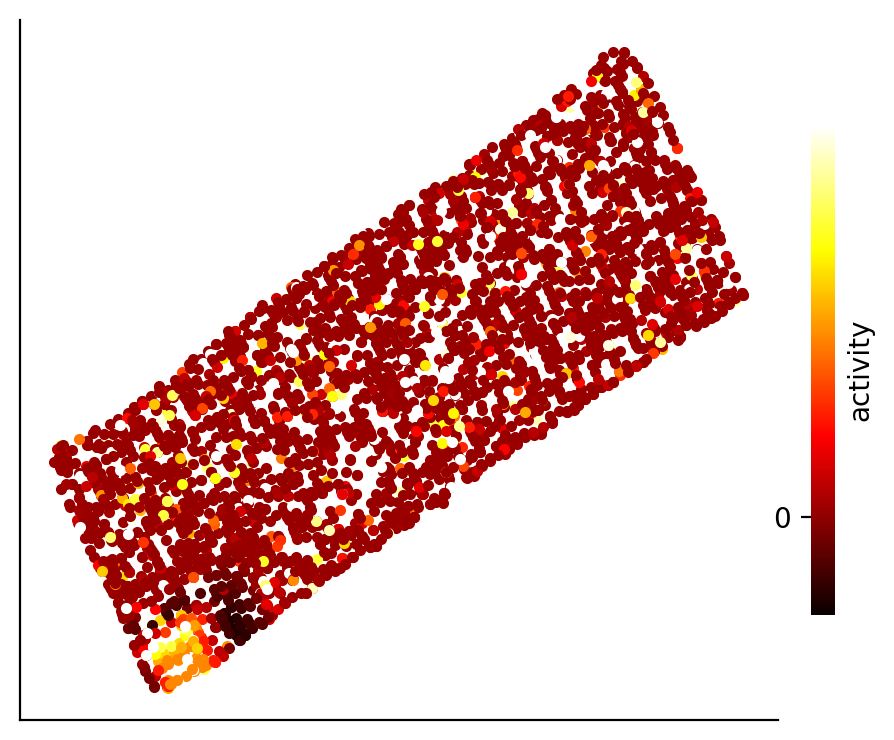

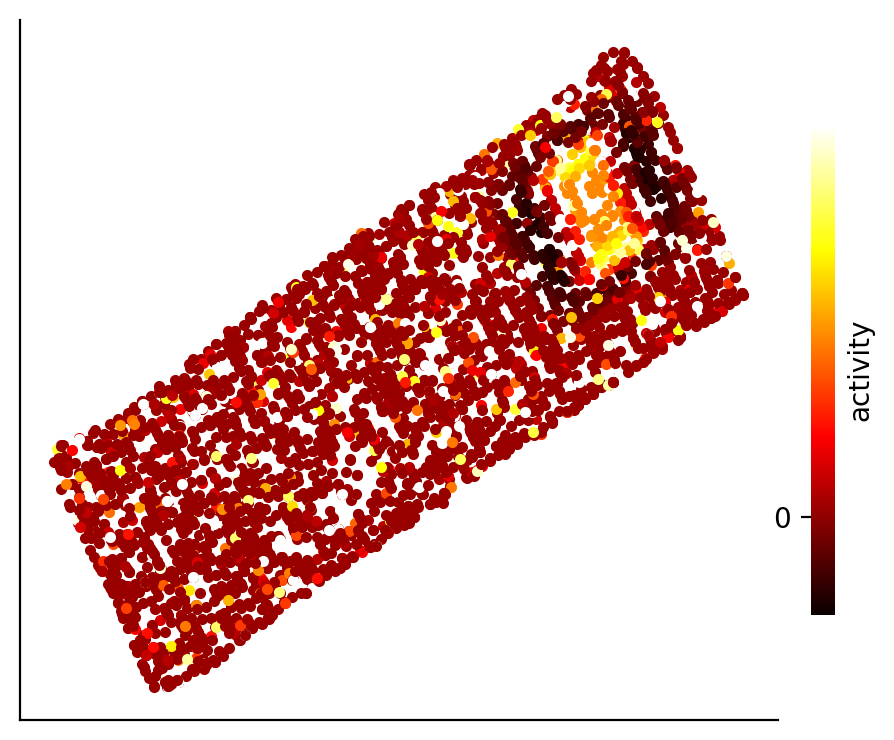

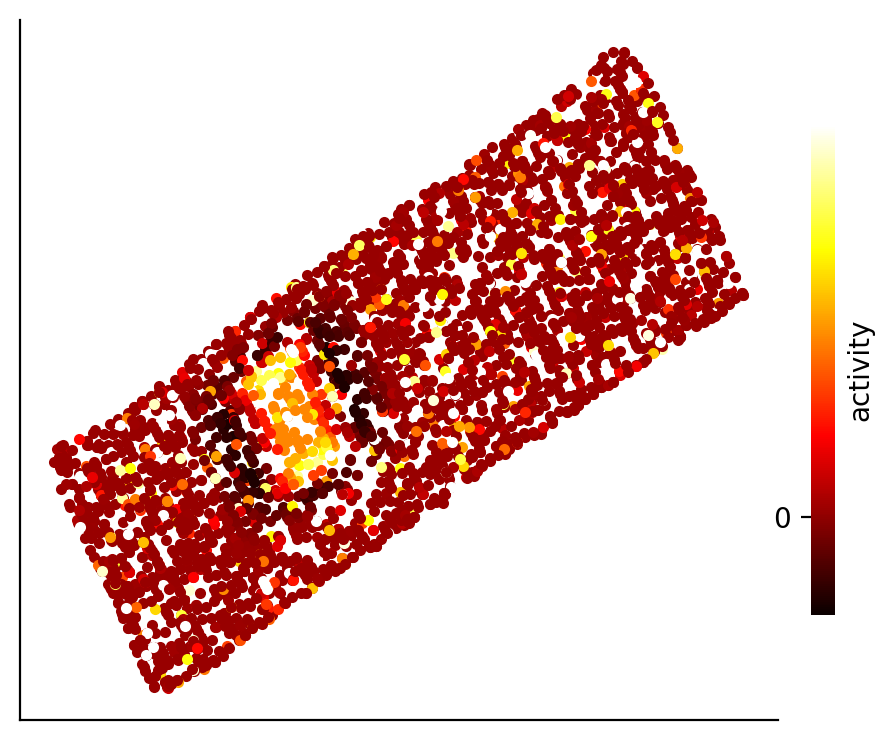

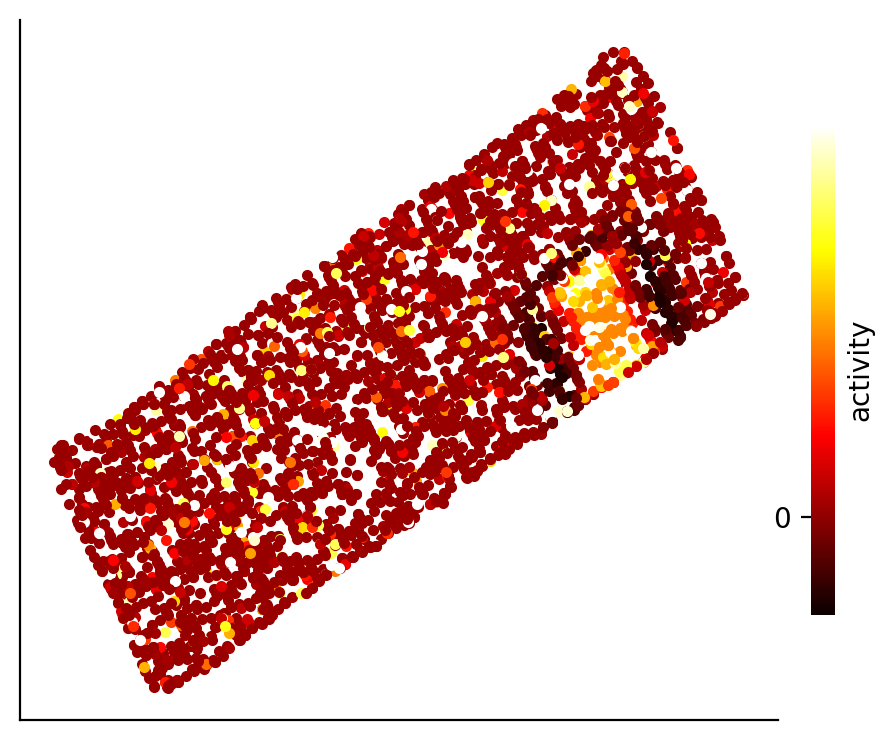

In [23]:
import matplotlib.colors as mcolors 
import matplotlib as mpl
for cellnum in (62, 236, 227, 135):

    lgn_scaled = (lgn_test - lgn_test.min()) / (lgn_test.max() - lgn_test.min())
    lgn_scaled = lgn_scaled.detach().cpu().numpy()


    plt.figure(figsize=(12,10))
    plt.subplot(2, 2, 1)    
    for i in range(z_s_y.shape[0]):
        red_blue = mcolors.to_rgb(mcolors.hsv_to_rgb([0.666 * (1-lgn_scaled[i,cellnum]), 1.0, 1.0]))
        blue_yellow = mcolors.to_rgb(mcolors.hsv_to_rgb([(0.1 + (0.777 - 0.1) * (1 - lgn_scaled[i,cellnum])), 1.0, 1.0]))
        plt.plot(-z_s_y[i,0], -z_s_y[i,1], 'o', color=mpl.colormaps['hot'](2.6*(lgn_scaled[i,cellnum]**2)), 
                markersize=4, 
                markeredgecolor='none', markeredgewidth=0.2)
        # plt.plot(-z_s_y[i,1], -z_s_y[i,0], 'o', color=red_blue, 
        #          markersize=2, 
        #          markeredgecolor='none', markeredgewidth=0.2)
    # plt.title("LGN shared")
    plt.xticks([]); plt.yticks([])
    axisWidthChange(0.9, 'l')
    axisHeightChange(0.9, 't')
    # plt.gca().set_frame_on(False)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)


    # Create a mappable object with the same colormap and normalization
    norm = mpl.colors.Normalize(vmin=lgn_scaled.min(), vmax=lgn_scaled.max())
    sm = mpl.cm.ScalarMappable(cmap=mpl.colormaps['hot'], norm=norm)
    sm.set_array([])  # You can set an empty list because the colorbar uses only the colormap and norm

    # Add the colorbar to the plot
    cax = plt.colorbar(sm, ax=plt.gca(), orientation='vertical').ax
    axisHeightChange(0.7, 'm', cax)
    cax.set_ylabel('activity')
    cax.set_frame_on(False)
    cax.yaxis.set_ticks_position('left')
    cax.set_yticks([0.2])
    cax.set_yticklabels(["0"])

    axisWidthChange(1.12, 'l')
    axisMove(0.03, 0, cax)

    plt.savefig("../Figures/cell_%d_onShared.svg" % cellnum, bbox_inches='tight')
    # plt.savefig("../Figures/cell_%d_onShared.png" % cellnum, bbox_inches='tight', dpi=300)

